# CS3807 Experiments 8 and 9 — ResNet50 with Attention (Corrected)

This notebook follows the **CS3807 assignment manual** and preserves the original notebook's dataset, preprocessing, attention-layer implementations, plotting helpers, evaluation metrics, and report/viva notes where appropriate.

**Important architecture correction:** attention is inserted *inside* the ResNet50 feature path. The attended tensor is passed through the remaining ResNet50 stage(s), e.g. `conv4_x → Channel Attention → Spatial Attention → conv5_x`, rather than being pooled and classified immediately at the insertion point. P2, P3 and P4 mean after `conv3_x`, `conv4_x` and `conv5_x`, respectively.

**Run from top to bottom in Google Colab.** Select a GPU if available. TensorFlow Flowers is downloaded by TensorFlow Datasets. The first run downloads ImageNet weights and the dataset. Set `EPOCHS` and `RUN_EXTENDED_ABLATIONS` near the top to manage runtime. This notebook intentionally clears old outputs/results so reported metrics cannot silently mix results from different model versions. Run the notebook to generate fresh results; no performance numbers are fabricated.

Outputs are saved under `results/`. Use only values generated by your own completed run in the report.


In [1]:
# Install required packages (run once)
!pip -q install tensorflow-datasets scikit-learn seaborn

In [1]:
import os, time, json, random, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 5       # For a quick test use 1; for final results use more epochs if time/GPU allows.
NUM_CLASSES = 5
AUTOTUNE = tf.data.AUTOTUNE
RESULT_DIR = "results"
os.makedirs(RESULT_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Task 1 — Load the Flowers dataset and define the data split

Create one reproducible 70% training, 15% validation, and 15% test split. Reusing these same examples across the experiments makes the comparisons more consistent. The input pipeline also applies the preprocessing expected by ResNet50.


In [2]:
import sys
import subprocess

try:
    import importlib_resources
except ImportError:
    print("Installing missing dependency: importlib_resources...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "importlib_resources"])

(ds_all, ds_info) = tfds.load(
    "tf_flowers",
    split="train",
    as_supervised=True,
    with_info=True,
    shuffle_files=False
)
class_names = ds_info.features["label"].names
print("Classes:", class_names)
print("Total images:", ds_info.splits["train"].num_examples)

# Collect file-independent image/label arrays for a reproducible stratified split.
images, labels = [], []
for image, label in tfds.as_numpy(ds_all):
    images.append(image)
    labels.append(int(label))
images = np.array(images, dtype=object)
labels = np.array(labels, dtype=np.int32)

all_idx = np.arange(len(labels))
train_idx, temp_idx = train_test_split(
    all_idx, test_size=0.30, random_state=SEED, stratify=labels
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED, stratify=labels[temp_idx]
)

print(f"Train: {len(train_idx)} ({len(train_idx)/len(labels):.1%})")
print(f"Validation: {len(val_idx)} ({len(val_idx)/len(labels):.1%})")
print(f"Test: {len(test_idx)} ({len(test_idx)/len(labels):.1%})")

Installing missing dependency: importlib_resources...


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.HBRPOI_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Total images: 3670
Train: 2569 (70.0%)
Validation: 550 (15.0%)
Test: 551 (15.0%)


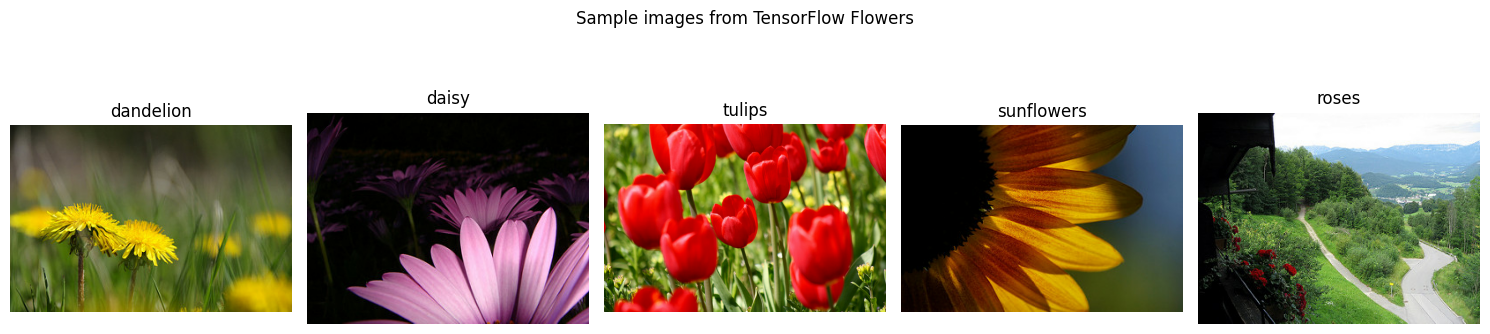

In [3]:
# Plot sample images from all five classes
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(15, 4))
for class_id, ax in enumerate(axes):
    sample_id = np.where(labels == class_id)[0][0]
    ax.imshow(images[sample_id])
    ax.set_title(class_names[class_id])
    ax.axis("off")
plt.suptitle("Sample images from TensorFlow Flowers")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/01_sample_images.png", dpi=160, bbox_inches="tight")
plt.show()

In [4]:
def preprocess_image(image, label, training=False):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    if training:
        image = tf.image.random_flip_left_right(image)
        image = tf.image.random_brightness(image, max_delta=0.08)
        image = tf.image.random_contrast(image, lower=0.9, upper=1.1)
    image = tf.keras.applications.resnet50.preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES)
    return image, label

def make_dataset(indices, training=False):
    # Convert object array to a list so TensorFlow can build a dataset from variable-sized images.
    subset_images = [images[i] for i in indices]
    subset_labels = labels[indices]
    ds = tf.data.Dataset.from_generator(
        lambda: iter(zip(subset_images, subset_labels)),
        output_signature=(
            tf.TensorSpec(shape=(None, None, 3), dtype=tf.uint8),
            tf.TensorSpec(shape=(), dtype=tf.int32)
        )
    )
    if training:
        ds = ds.shuffle(len(indices), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda x, y: preprocess_image(x, y, training), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_idx, training=True)
val_ds = make_dataset(val_idx)
test_ds = make_dataset(test_idx)

## Task 2 — Create the attention modules

- **Channel attention** assigns different weights to feature channels.
- **Spatial attention** assigns weights to positions in a feature map.
- **Channel followed by spatial attention** applies these two operations in sequence.
- **Self-attention** lets spatial positions use information from other positions when forming their representations.


In [5]:
from tensorflow.keras import layers, Model

@tf.keras.utils.register_keras_serializable()
class ChannelAttention(layers.Layer):
    def __init__(self, ratio=16, **kwargs):
        super().__init__(**kwargs)
        self.ratio = ratio
    def build(self, input_shape):
        channels = int(input_shape[-1])
        hidden = max(channels // self.ratio, 1)
        self.pool = layers.GlobalAveragePooling2D(keepdims=True)
        self.fc1 = layers.Conv2D(hidden, 1, activation="relu")
        self.fc2 = layers.Conv2D(channels, 1, activation="sigmoid")
        super().build(input_shape)
    def call(self, x):
        weights = self.fc2(self.fc1(self.pool(x)))
        return x * weights
    def get_config(self):
        return {**super().get_config(), "ratio": self.ratio}

@tf.keras.utils.register_keras_serializable()
class SpatialAttention(layers.Layer):
    def __init__(self, kernel_size=7, **kwargs):
        super().__init__(**kwargs)
        self.kernel_size = kernel_size
        self.conv = layers.Conv2D(1, kernel_size, padding="same", activation="sigmoid", use_bias=False)
    def call(self, x):
        avg_map = tf.reduce_mean(x, axis=-1, keepdims=True)
        max_map = tf.reduce_max(x, axis=-1, keepdims=True)
        weights = self.conv(tf.concat([avg_map, max_map], axis=-1))
        return x * weights
    def get_config(self):
        return {**super().get_config(), "kernel_size": self.kernel_size}

@tf.keras.utils.register_keras_serializable()
class LiteSelfAttention(layers.Layer):
    def __init__(self, key_dim=64, **kwargs):
        super().__init__(**kwargs)
        self.key_dim = key_dim
    def build(self, input_shape):
        channels = int(input_shape[-1])
        d = min(self.key_dim, channels)
        self.q = layers.Conv2D(d, 1, use_bias=False)
        self.k = layers.Conv2D(d, 1, use_bias=False)
        self.v = layers.Conv2D(channels, 1, use_bias=False)
        self.gamma = self.add_weight(name="gamma", shape=(), initializer="zeros", trainable=True)
        super().build(input_shape)
    def call(self, x):
        shape = tf.shape(x)
        b, h, w = shape[0], shape[1], shape[2]
        q = tf.reshape(self.q(x), [b, h*w, -1])
        k = tf.reshape(self.k(x), [b, h*w, -1])
        v = tf.reshape(self.v(x), [b, h*w, -1])
        scores = tf.matmul(q, k, transpose_b=True) / tf.sqrt(tf.cast(tf.shape(k)[-1], tf.float32))
        weights = tf.nn.softmax(scores, axis=-1)
        attended = tf.matmul(weights, v)
        attended = tf.reshape(attended, [b, h, w, tf.shape(v)[-1]])
        return x + self.gamma * attended
    def get_config(self):
        return {**super().get_config(), "key_dim": self.key_dim}

def apply_attention(x, attention="none", order="channel_spatial", kernel_size=7):
    if attention in ("channel", "channel_spatial", "cbam"):
        x = ChannelAttention(name="channel_attention")(x)
    if attention in ("spatial", "channel_spatial", "cbam"):
        x = SpatialAttention(kernel_size=kernel_size, name="spatial_attention")(x)
    if attention == "spatial_channel":
        x = SpatialAttention(kernel_size=kernel_size, name="spatial_attention")(x)
        x = ChannelAttention(name="channel_attention")(x)
    if attention == "self":
        x = LiteSelfAttention(name="self_attention")(x)
    return x

## Task 3 — Define and train the models

The assignment's stage positions are:

- **P2:** after `conv3_x`, `conv3_block4_out` (28 × 28 × 512)
- **P3:** after `conv4_x`, `conv4_block6_out` (14 × 14 × 1024)
- **P4:** after `conv5_x`, `conv5_block3_out` (7 × 7 × 2048)

Unlike the original implementation, the corrected model resumes the remaining ResNet50 blocks after attention. For example, P3 attention feeds the resulting 14 × 14 × 1024 tensor into `conv5_x`. The baseline is the complete pretrained ResNet50 followed by global average pooling, dropout, and a five-class softmax head.

All mandatory models use the same fixed data split, preprocessing, augmentation policy, batch size, optimizer and epoch budget. This is a controlled comparison, although GPU/runtime and stochastic optimization can still cause variation. The backbone is frozen for the main comparison to keep the run tractable; optional fine-tuning is described in the report checklist.


In [6]:
def apply_attention(x, attention="none", order="channel_spatial", kernel_size=7):
    """Apply an attention block without changing H, W, or C."""
    if attention in ("channel", "channel_spatial", "cbam", "combined_all"):
        x = ChannelAttention(name="channel_attention")(x)
    if attention in ("spatial", "channel_spatial", "cbam", "combined_all"):
        x = SpatialAttention(kernel_size=kernel_size, name="spatial_attention")(x)
    if attention == "spatial_channel":
        x = SpatialAttention(kernel_size=kernel_size, name="spatial_attention")(x)
        x = ChannelAttention(name="channel_attention")(x)
    if attention in ("self", "combined_all"):
        x = LiteSelfAttention(name="self_attention")(x)
    return x

STAGE_LAYERS = {
    "P2": "conv3_block4_out",  # after conv3_x; next stage is conv4_x
    "P3": "conv4_block6_out",  # after conv4_x; next stage is conv5_x
    "P4": "conv5_block3_out",  # after conv5_x
}


def build_model(attention="none", position="P4", kernel_size=7,
                order="channel_spatial", extra_mechanism=None,
                train_backbone=False, positions=None):
    """Build a full ResNet50 path with attention inserted between stages.

    `positions` supports multi-stage experiments, e.g. ["P3", "P4"].
    Attention output always flows through all later backbone stages.
    """
    base = tf.keras.applications.ResNet50(
        include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    positions = list(positions) if positions is not None else [position]
    positions = [p.upper() for p in positions]
    order_index = {"P2": 2, "P3": 3, "P4": 4}
    if any(p not in STAGE_LAYERS for p in positions):
        raise ValueError("positions must contain P2, P3 and/or P4")
    if positions != sorted(positions, key=lambda p: order_index[p]):
        raise ValueError("positions must be ordered from early to late stage")
    if attention == "none":
        positions = []

    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    if not positions:
        backbone = Model(base.input, base.output, name="resnet50_full")
        backbone.trainable = train_backbone
        x = backbone(inputs, training=False)
    else:
        # Execute the network segment-by-segment so each attended tensor replaces
        # the original stage output before the next ResNet stage consumes it.
        current_input = inputs
        current_tensor = None
        previous_position = None
        for idx, pos in enumerate(positions):
            stage_tensor = base.get_layer(STAGE_LAYERS[pos]).output
            if idx == 0:
                segment = Model(base.input, stage_tensor, name=f"resnet50_to_{pos}")
                segment.trainable = train_backbone
                x = segment(current_input, training=False)
            else:
                segment = Model(current_tensor, stage_tensor, name=f"resnet50_{previous_position}_to_{pos}")
                segment.trainable = train_backbone
                x = segment(x, training=False)
            if attention == "order":
                x = apply_attention(x, "spatial_channel" if order == "spatial_channel" else "channel_spatial", kernel_size)
            elif attention == "extra_se":
                channels = int(x.shape[-1])
                z = layers.GlobalAveragePooling2D(keepdims=True, name=f"se_pool_{pos}")(x)
                z = layers.Conv2D(max(channels // 16, 1), 1, activation="relu", name=f"se_reduce_{pos}")(z)
                z = layers.Conv2D(channels, 1, activation="sigmoid", name=f"se_expand_{pos}")(z)
                x = layers.Multiply(name=f"se_scale_{pos}")([x, z])
            elif attention == "extra_eca":
                channels = int(x.shape[-1])
                z = layers.GlobalAveragePooling2D(name=f"eca_pool_{pos}")(x)
                z = layers.Reshape((channels, 1), name=f"eca_reshape_in_{pos}")(z)
                z = layers.Conv1D(1, 3, padding="same", use_bias=False, name=f"eca_conv_{pos}")(z)
                z = layers.Activation("sigmoid", name=f"eca_sigmoid_{pos}")(z)
                z = layers.Reshape((1, 1, channels), name=f"eca_reshape_out_{pos}")(z)
                x = layers.Multiply(name=f"eca_scale_{pos}")([x, z])
            else:
                # Give each module unique names for multi-stage attention.
                if len(positions) > 1:
                    if attention in ("channel", "channel_spatial", "cbam", "combined_all"):
                        x = ChannelAttention(name=f"channel_attention_{pos}")(x)
                    if attention in ("spatial", "channel_spatial", "cbam", "combined_all"):
                        x = SpatialAttention(kernel_size=kernel_size, name=f"spatial_attention_{pos}")(x)
                    if attention == "spatial_channel":
                        x = SpatialAttention(kernel_size=kernel_size, name=f"spatial_attention_{pos}")(x)
                        x = ChannelAttention(name=f"channel_attention_{pos}")(x)
                    if attention in ("self", "combined_all"):
                        x = LiteSelfAttention(name=f"self_attention_{pos}")(x)
                else:
                    x = apply_attention(x, attention, order, kernel_size)
            current_tensor = base.get_layer(STAGE_LAYERS[pos]).output
            previous_position = pos
        # Continue from the last attended stage through all remaining ResNet blocks.
        last_pos = positions[-1]
        if last_pos != "P4":
            tail = Model(current_tensor, base.output, name=f"resnet50_{last_pos}_to_output")
            tail.trainable = train_backbone
            x = tail(x, training=False)

    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dropout(0.3, name="dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="flower_predictions")(x)
    model = Model(inputs, outputs, name=f"ResNet50_{attention}_{'_'.join(positions) if positions else 'baseline'}")
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    return model


def train_one(name, attention="none", position="P4", kernel_size=7,
              order="channel_spatial", positions=None):
    print("\nTraining:", name)
    model = build_model(attention=attention, position=position, kernel_size=kernel_size,
                        order=order, positions=positions)
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=1, min_lr=1e-6)
    ]
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                        callbacks=callbacks, verbose=1)
    return model, history

# Mandatory attention-type ablation at P3, position ablation for channel+spatial,
# and the required combined channel+spatial+self-attention variant.
experiment_specs = [
    ("Baseline", "none", "P4", None),
    ("Channel_P3", "channel", "P3", None),
    ("Spatial_P3", "spatial", "P3", None),
    ("ChannelSpatial_P3", "channel_spatial", "P3", None),
    ("ChannelSpatial_P2", "channel_spatial", "P2", None),
    ("ChannelSpatial_P4", "channel_spatial", "P4", None),
    ("SelfAttention_P3", "self", "P3", None),
    ("CombinedAll_P3", "combined_all", "P3", None),
    ("ChannelSpatial_P3_P4", "channel_spatial", "P3", ["P3", "P4"]),
]
models, histories = {}, {}
for name, attention, position, positions in experiment_specs:
    models[name], histories[name] = train_one(name, attention, position, positions=positions)
    models[name].save(f"{RESULT_DIR}/{name}.keras")
    with open(f"{RESULT_DIR}/{name}_history.json", "w") as f:
        json.dump({k: [float(v) for v in vals] for k, vals in histories[name].history.items()}, f)



Training: Baseline
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/5
    161/Unknown 40s 84ms/step - accuracy: 0.6174 - loss: 1.0523

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


161/161 ━━━━━━━━━━━━━━━━━━━━ 49s 144ms/step - accuracy: 0.7388 - loss: 0.7074 - val_accuracy: 0.8964 - val_loss: 0.3185 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 11s 64ms/step - accuracy: 0.8875 - loss: 0.3264 - val_accuracy: 0.9273 - val_loss: 0.2581 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 22s 72ms/step - accuracy: 0.9062 - loss: 0.2519 - val_accuracy: 0.8927 - val_loss: 0.2903 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 116ms/step - accuracy: 0.9381 - loss: 0.1862 - val_accuracy: 0.9273 - val_loss: 0.2381 - learning_rate: 3.0000e-04
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 123ms/step - accuracy: 0.9432 - loss: 0.1767 - val_accuracy: 0.9255 - val_loss: 0.2309 - learning_rate: 3.0000e-04

Training: Channel_P3
Epoch 1/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 39s 161ms/step - accuracy: 0.7661 - loss: 0.6049 - val_accuracy: 0.8891 - val_loss: 0.3067 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 22s 78ms/step - acc

## Task 4 — Plot training and validation curves

Use the training histories to compare accuracy and loss over the epochs. Training curves show how the models fit the training data, while validation curves help reveal whether that improvement carries over to unseen examples.


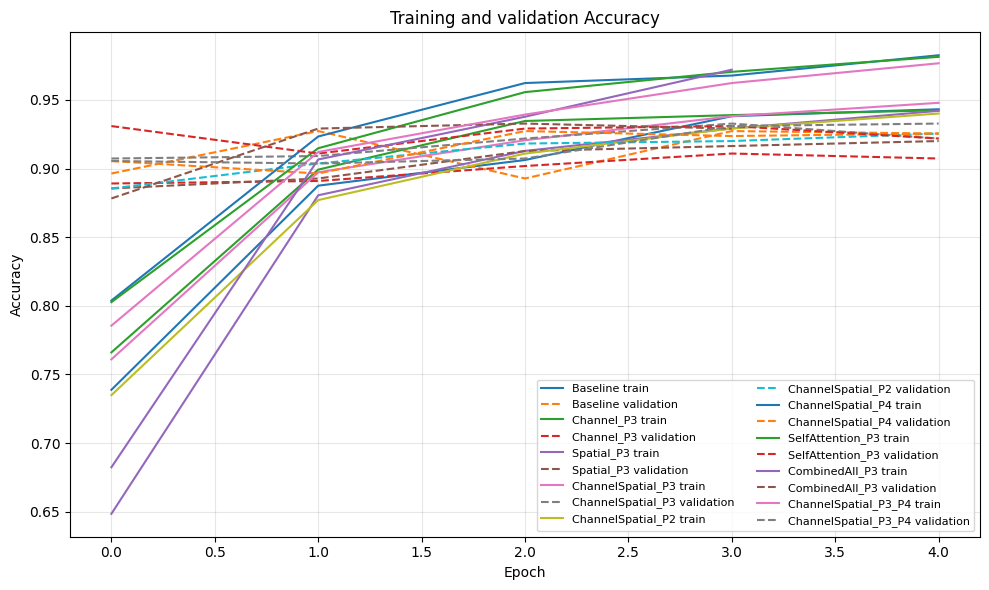

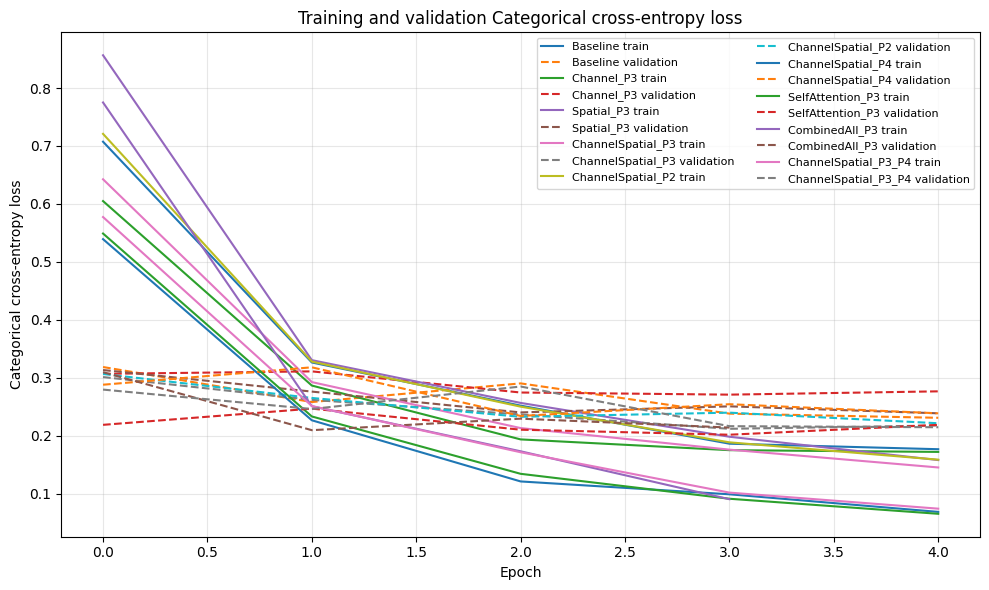

In [7]:
def plot_learning_curves(histories, metric, ylabel, filename):
    plt.figure(figsize=(10, 6))
    for name, hist in histories.items():
        if metric in hist.history:
            plt.plot(hist.history[metric], label=f"{name} train")
        val_metric = "val_" + metric
        if val_metric in hist.history:
            plt.plot(hist.history[val_metric], linestyle="--", label=f"{name} validation")
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(f"Training and validation {ylabel}")
    plt.legend(fontsize=8, ncol=2)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{RESULT_DIR}/{filename}", dpi=160, bbox_inches="tight")
    plt.show()

plot_learning_curves(histories, "accuracy", "Accuracy", "02_accuracy_curves.png")
plot_learning_curves(histories, "loss", "Categorical cross-entropy loss", "03_loss_curves.png")

## Task 5 — Evaluate the models on the test set

Calculate the required test metrics and record each model's parameter count and inference time. The confusion matrices provide a class-by-class view of the predictions, complementing the overall scores.


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Trainable Parameters,Total Parameters,Inference Time (s/image)
0,Baseline,0.9183,0.9165,0.9192,0.9175,10245,23597957,0.0170
1,Channel_P3,0.9129,0.9138,0.9140,0.9118,142405,23730117,0.0178
2,Spatial_P3,0.9183,0.9175,0.9194,0.9182,10343,23598055,0.0172
3,ChannelSpatial_P3,0.9238,0.9223,0.9235,0.9227,142503,23730215,0.0176
4,ChannelSpatial_P2,0.9093,0.9092,0.9106,0.9094,43655,23631367,0.0176
5,ChannelSpatial_P4,0.9220,0.9208,0.9235,0.9219,536807,24124519,0.0174
6,SelfAttention_P3,0.9365,0.9358,0.9361,0.9356,1189894,24777606,0.0178
7,CombinedAll_P3,0.9129,0.9149,0.9100,0.9122,1322152,24909864,0.0181
8,ChannelSpatial_P3_P4,0.9201,0.9193,0.9201,0.9197,669065,24256777,0.0179


Saved: results/results_metrics.csv


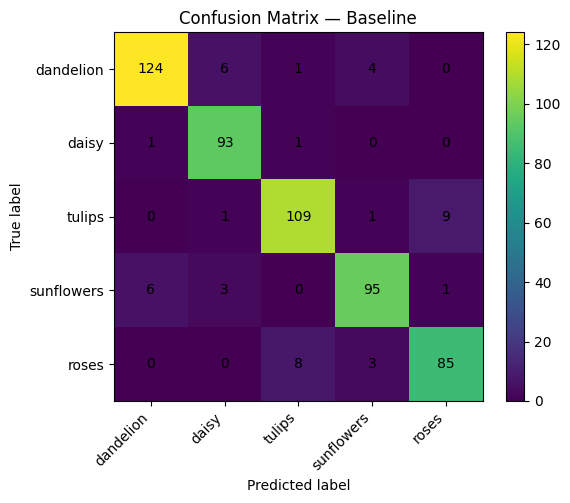

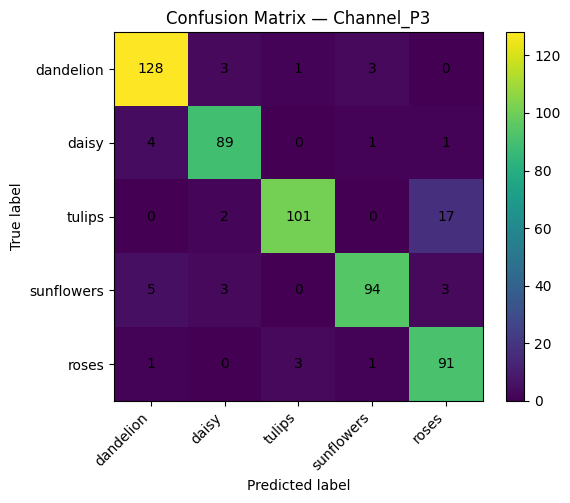

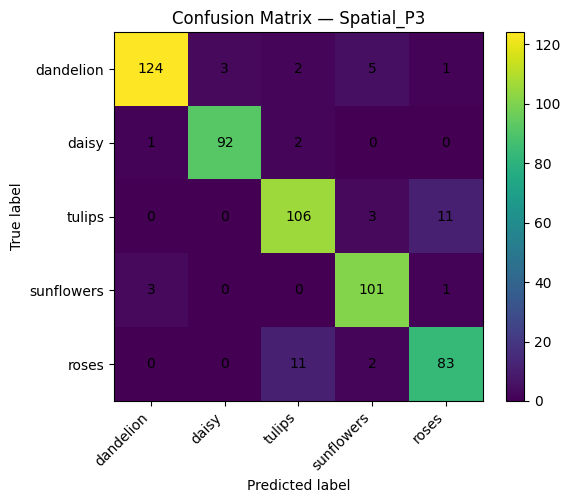

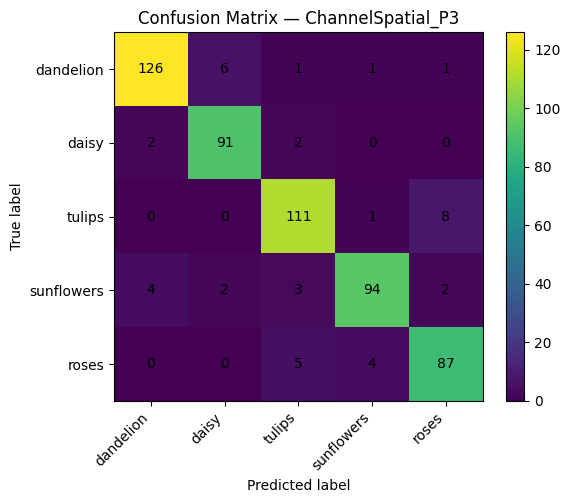

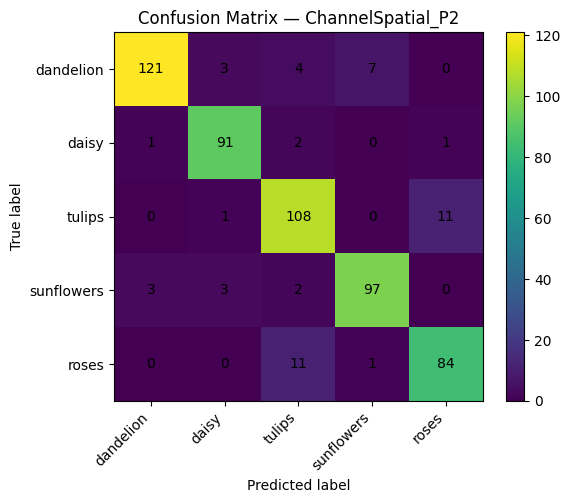

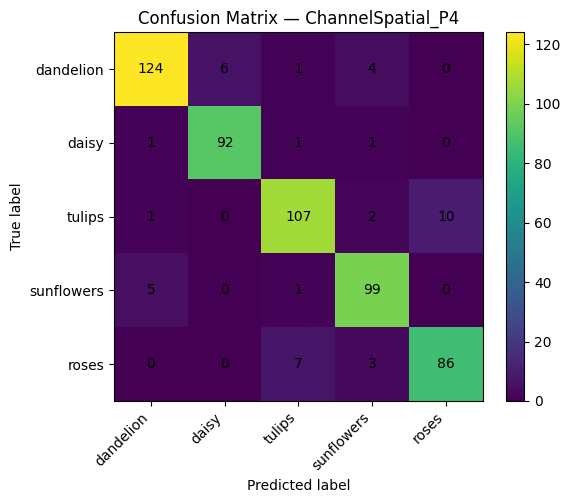

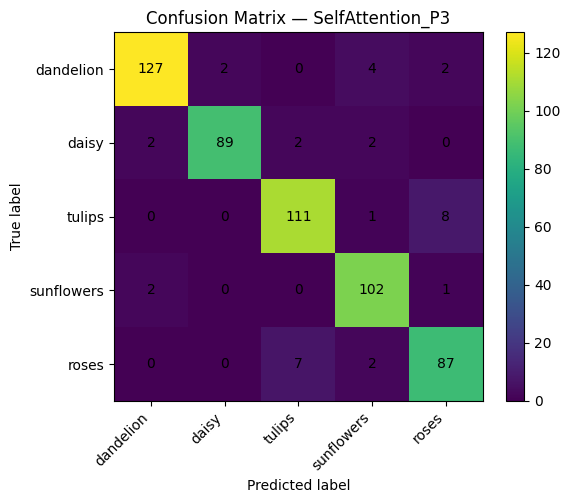

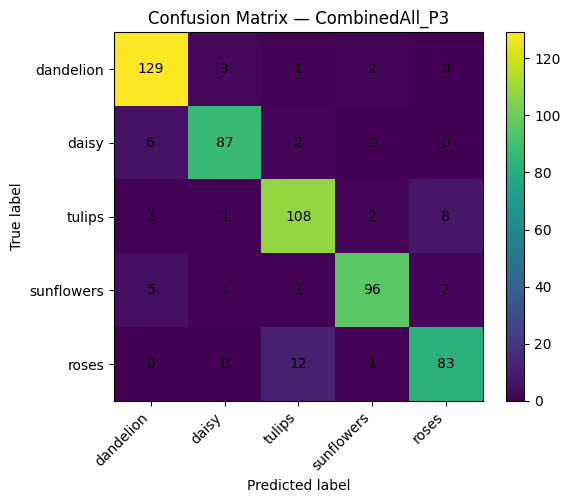

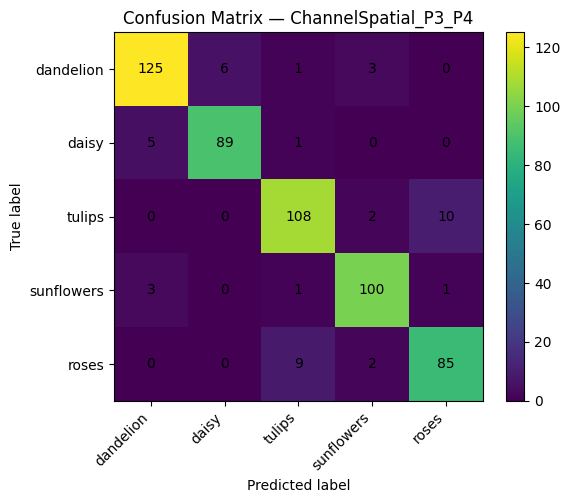


Classification report: Baseline
              precision    recall  f1-score   support

   dandelion       0.95      0.92      0.93       135
       daisy       0.90      0.98      0.94        95
      tulips       0.92      0.91      0.91       120
  sunflowers       0.92      0.90      0.91       105
       roses       0.89      0.89      0.89        96

    accuracy                           0.92       551
   macro avg       0.92      0.92      0.92       551
weighted avg       0.92      0.92      0.92       551


Classification report: ChannelSpatial_P3
              precision    recall  f1-score   support

   dandelion       0.95      0.93      0.94       135
       daisy       0.92      0.96      0.94        95
      tulips       0.91      0.93      0.92       120
  sunflowers       0.94      0.90      0.92       105
       roses       0.89      0.91      0.90        96

    accuracy                           0.92       551
   macro avg       0.92      0.92      0.92       551
we

In [8]:
def time_inference(model, repeats=3):
    # Warm up model first
    for batch_x, _ in test_ds.take(1):
        _ = model(batch_x, training=False)
    total_images, total_seconds = 0, 0.0
    for _ in range(repeats):
        for batch_x, _ in test_ds:
            start = time.perf_counter()
            _ = model(batch_x, training=False)
            # Force completion for GPU timing
            _ = _.numpy()
            total_seconds += time.perf_counter() - start
            total_images += int(batch_x.shape[0])
    return total_seconds / max(total_images, 1)

def evaluate_model(model, name):
    y_true, y_prob = [], []
    for xb, yb in test_ds:
        probs = model.predict(xb, verbose=0)
        y_prob.extend(probs)
        y_true.extend(np.argmax(yb.numpy(), axis=1))
    y_true = np.array(y_true)
    y_pred = np.argmax(np.array(y_prob), axis=1)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Trainable Parameters": int(sum(np.prod(v.shape) for v in model.trainable_variables)),
        "Total Parameters": int(model.count_params()),
        "Inference Time (s/image)": time_inference(model),
        "y_true": y_true, "y_pred": y_pred
    }

results = []
predictions = {}
for name, model in models.items():
    r = evaluate_model(model, name)
    predictions[name] = (r.pop("y_true"), r.pop("y_pred"))
    results.append(r)

results_df = pd.DataFrame(results)
display(results_df.round(4))
results_df.to_csv(f"{RESULT_DIR}/results_metrics.csv", index=False)
print("Saved:", f"{RESULT_DIR}/results_metrics.csv")

for name in models:
    y_true, y_pred = predictions[name]
    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    plt.figure(figsize=(6, 5))
    plt.imshow(cm, interpolation="nearest")
    plt.title(f"Confusion Matrix — {name}")
    plt.colorbar()
    ticks = np.arange(NUM_CLASSES)
    plt.xticks(ticks, class_names, rotation=45, ha="right")
    plt.yticks(ticks, class_names)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            plt.text(j, i, cm[i, j], ha="center", va="center")
    plt.tight_layout()
    plt.savefig(f"{RESULT_DIR}/confusion_{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

# Detailed class-wise report for the baseline and selected attention model
for name in ["Baseline", "ChannelSpatial_P3"]:
    y_true, y_pred = predictions[name]
    print("\nClassification report:", name)
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

## Task 6 — Visualize the performance comparison

Generate plots comparing test accuracy, macro-F1, model size versus accuracy, and inference time versus macro-F1. Read these together rather than judging a model from one metric alone.


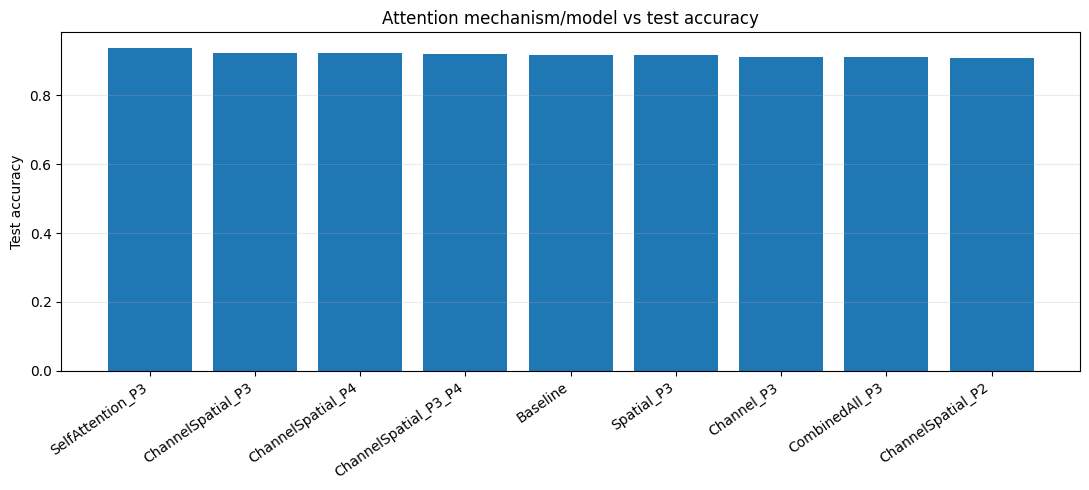

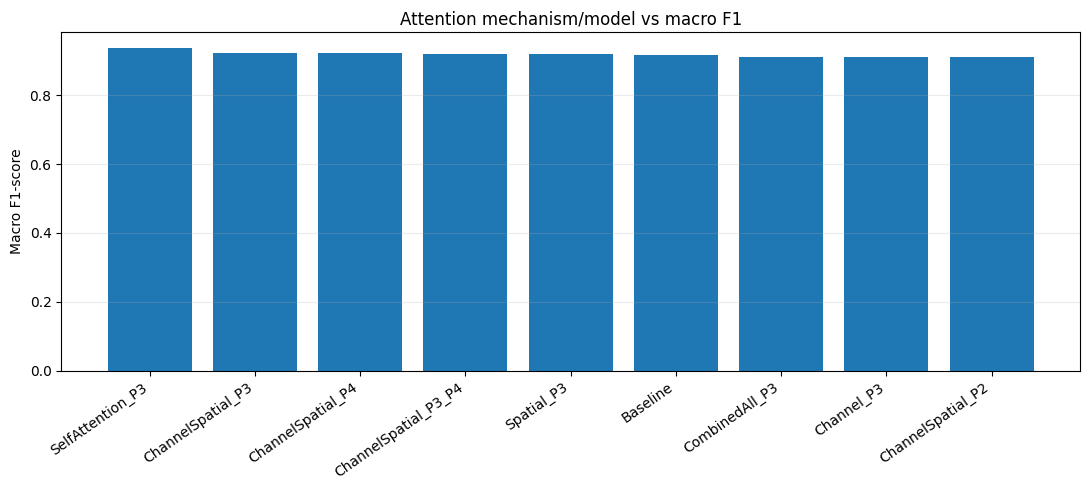

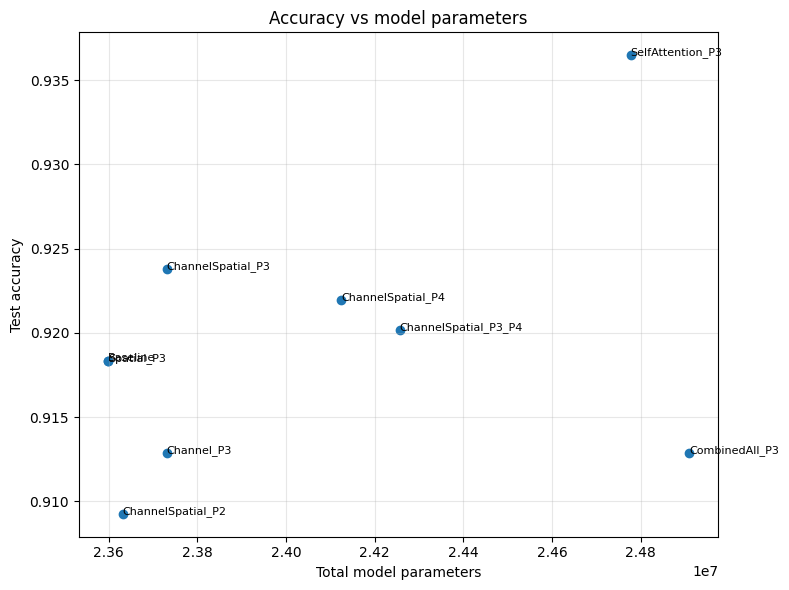

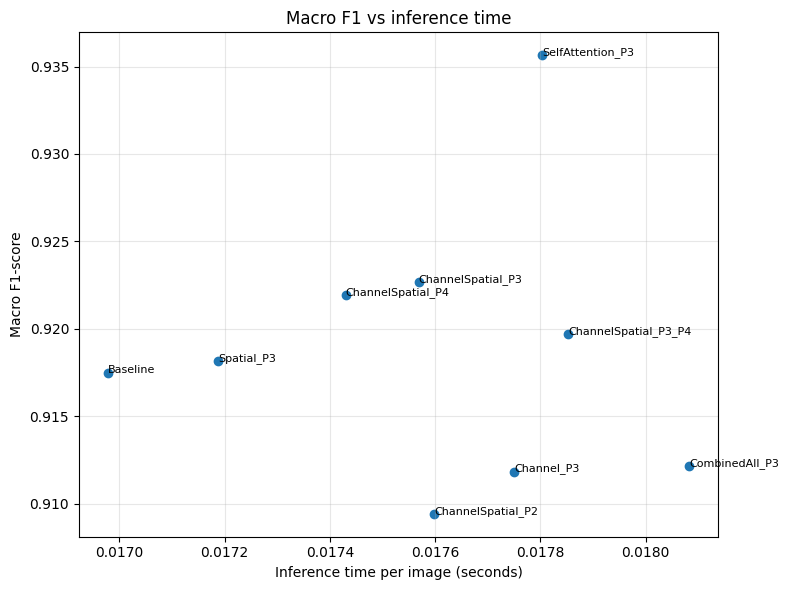

In [9]:
def bar_plot(metric, title, ylabel, filename):
    data = results_df.sort_values(metric, ascending=False)
    plt.figure(figsize=(11, 5))
    plt.bar(data["Model"], data[metric])
    plt.xticks(rotation=35, ha="right")
    plt.title(title)
    plt.ylabel(ylabel)
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.savefig(f"{RESULT_DIR}/{filename}", dpi=160, bbox_inches="tight")
    plt.show()

bar_plot("Accuracy", "Attention mechanism/model vs test accuracy", "Test accuracy", "04_accuracy_comparison.png")
bar_plot("Macro F1", "Attention mechanism/model vs macro F1", "Macro F1-score", "05_macro_f1_comparison.png")

plt.figure(figsize=(8, 6))
plt.scatter(results_df["Total Parameters"], results_df["Accuracy"])
for _, row in results_df.iterrows():
    plt.annotate(row["Model"], (row["Total Parameters"], row["Accuracy"]), fontsize=8)
plt.xlabel("Total model parameters")
plt.ylabel("Test accuracy")
plt.title("Accuracy vs model parameters")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/06_accuracy_vs_parameters.png", dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(results_df["Inference Time (s/image)"], results_df["Macro F1"])
for _, row in results_df.iterrows():
    plt.annotate(row["Model"], (row["Inference Time (s/image)"], row["Macro F1"]), fontsize=8)
plt.xlabel("Inference time per image (seconds)")
plt.ylabel("Macro F1-score")
plt.title("Macro F1 vs inference time")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/07_f1_vs_inference_time.png", dpi=160, bbox_inches="tight")
plt.show()

## Task 7 — Inspect attention and feature visualizations

The following helpers display attention responses, channel weights, feature maps, and image overlays. Run them after training so the visualizations use the models created in Task 3.


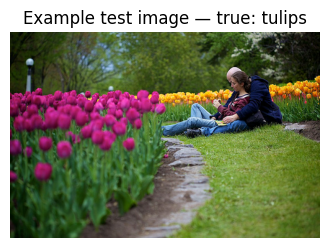

Baseline | true: tulips | predicted: tulips
ChannelSpatial_P3 | true: tulips | predicted: tulips


In [10]:
def get_test_image(index=0):
    # The test split order follows test_idx. Return a raw image and true class label.
    raw = images[test_idx[index]]
    label = labels[test_idx[index]]
    resized = tf.image.resize(raw, (IMG_SIZE, IMG_SIZE)).numpy().astype(np.float32)
    model_input = tf.keras.applications.resnet50.preprocess_input(resized.copy())
    return raw, resized, label, np.expand_dims(model_input, axis=0)

def show_overlay(image, heatmap, title, filename):
    heatmap = np.squeeze(heatmap)
    heatmap = tf.image.resize(heatmap[..., None], (IMG_SIZE, IMG_SIZE)).numpy().squeeze()
    heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
    plt.figure(figsize=(5, 5))
    plt.imshow(image.astype("uint8"))
    plt.imshow(heatmap, alpha=0.45, cmap="jet")
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(f"{RESULT_DIR}/{filename}", dpi=160, bbox_inches="tight")
    plt.show()

def get_attention_layer_model(model, layer_name, input_tensor):
    layer = model.get_layer(layer_name)
    return Model(model.inputs, layer.output)(input_tensor, training=False)

# Show one representative test image and predicted classes
raw_img, resized_img, true_label, x_img = get_test_image(0)
plt.figure(figsize=(4, 4))
plt.imshow(raw_img)
plt.title(f"Example test image — true: {class_names[true_label]}")
plt.axis("off")
plt.show()

for name in ["Baseline", "ChannelSpatial_P3"]:
    pred = int(np.argmax(models[name].predict(x_img, verbose=0)[0]))
    print(name, "| true:", class_names[true_label], "| predicted:", class_names[pred])

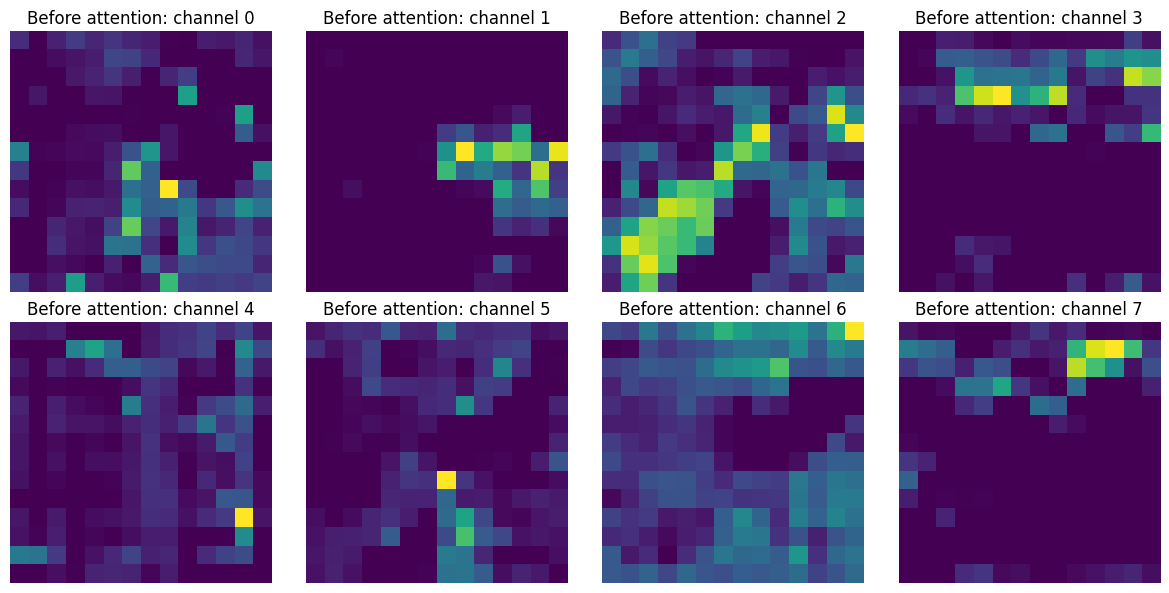

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['image']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


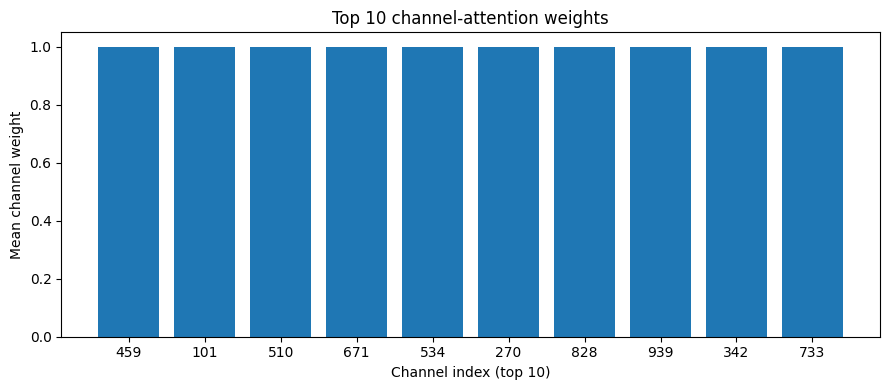

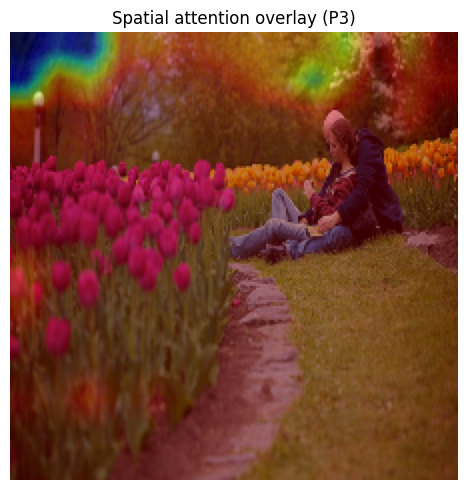

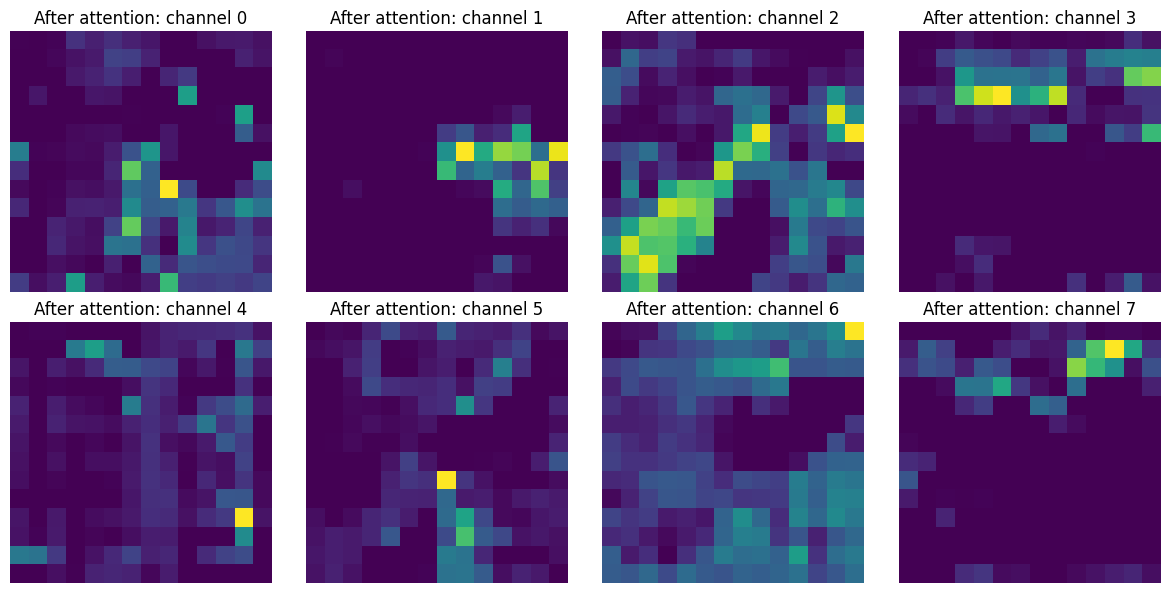

In [11]:

# Feature maps before/after attention, spatial map, channel weights

# P3 feature layer in the shared pretrained ResNet50
probe_base = tf.keras.applications.ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

probe = Model(
    probe_base.input,
    probe_base.get_layer("conv4_block6_out").output
)

features = probe(x_img, training=False).numpy()[0]

# Before-attention feature maps: display first 8 channels
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(features[:, :, i], cmap="viridis")
    ax.set_title(f"Before attention: channel {i}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    f"{RESULT_DIR}/08_features_before_attention.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()


# Generate internal attention weights from the trained
# channel + spatial P3 model
m = models["ChannelSpatial_P3"]

channel_layer = m.get_layer("channel_attention")
spatial_layer = m.get_layer("spatial_attention")


# Build a probe that returns features before channel attention
pre_attention_tensor = channel_layer.input
pre_probe = Model(m.inputs, pre_attention_tensor)

pre_feat = pre_probe(x_img, training=False)

# Calculate channel-attention weights
# Read the learned sigmoid channel weights directly (stable; no division by features).
channel_weights = channel_layer.fc2(channel_layer.fc1(channel_layer.pool(pre_feat)))
channel_importance = channel_weights.numpy()[0, 0, 0, :]

top_k = np.argsort(channel_importance)[-10:][::-1]


# Plot top 10 channel-attention weights
plt.figure(figsize=(9, 4))

plt.bar(
    [str(int(i)) for i in top_k],
    channel_importance[top_k]
)

plt.xlabel("Channel index (top 10)")
plt.ylabel("Mean channel weight")
plt.title("Top 10 channel-attention weights")

plt.tight_layout()
plt.savefig(
    f"{RESULT_DIR}/09_channel_attention_weights.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()


# Spatial attention module receives channel-refined features
channel_output_tensor = channel_layer.output

spatial_input_probe = Model(
    m.inputs,
    channel_output_tensor
)

channel_refined = spatial_input_probe(
    x_img,
    training=False
)


# FIX: Convert each TensorFlow tensor to NumPy only once
avg_map = tf.reduce_mean(channel_refined, axis=-1, keepdims=True)
max_map = tf.reduce_max(channel_refined, axis=-1, keepdims=True)
spatial_response = tf.nn.sigmoid(spatial_layer.conv(tf.concat([avg_map, max_map], axis=-1))).numpy()

show_overlay(
    resized_img,
    spatial_response[0],
    "Spatial attention overlay (P3)",
    "10_spatial_attention_overlay.png"
)


# Feature maps after attention
post_probe = Model(
    m.inputs,
    spatial_layer.output
)

post_feat = post_probe(
    x_img,
    training=False
).numpy()[0]


# Display first 8 channels after attention
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(post_feat[:, :, i], cmap="viridis")
    ax.set_title(f"After attention: channel {i}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    f"{RESULT_DIR}/11_features_after_attention.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()


## Task 8 — Generate Grad-CAM explanations

Grad-CAM is a post-training explanation method. It uses gradients of a predicted class score with respect to a convolutional feature map to create a heatmap. The implementation below uses the selected stage's final convolutional feature layer.


In [12]:

for name in ["Baseline", "ChannelSpatial_P3"]:
    print(f"\n{name}")

    for layer in models[name].layers:
        print(
            layer.name,
            type(layer).__name__,
            getattr(layer, "output_shape", "shape unavailable")
        )



Baseline
image InputLayer shape unavailable
resnet50_full Functional (None, 7, 7, 2048)
global_average_pooling GlobalAveragePooling2D shape unavailable
dropout Dropout shape unavailable
flower_predictions Dense shape unavailable

ChannelSpatial_P3
image InputLayer shape unavailable
resnet50_to_P3 Functional (None, 14, 14, 1024)
channel_attention ChannelAttention shape unavailable
spatial_attention SpatialAttention shape unavailable
resnet50_P3_to_output Functional (None, 7, 7, 2048)
global_average_pooling GlobalAveragePooling2D shape unavailable
dropout Dropout shape unavailable
flower_predictions Dense shape unavailable


In [13]:

for name in ["Baseline", "ChannelSpatial_P3"]:
    model = models[name]

    print(f"\nModel: {name}")

    for layer in model.layers:
        if isinstance(layer, tf.keras.Model):
            print("Nested model:", layer.name)
            print("Nested layers:")

            for sublayer in layer.layers:
                if "conv4_block6_out" in sublayer.name or \
                   "conv5_block3_out" in sublayer.name:
                    print("  Candidate:", sublayer.name)



Model: Baseline
Nested model: resnet50_full
Nested layers:
  Candidate: conv4_block6_out
  Candidate: conv5_block3_out

Model: ChannelSpatial_P3
Nested model: resnet50_to_P3
Nested layers:
  Candidate: conv4_block6_out
Nested model: resnet50_P3_to_output
Nested layers:
  Candidate: conv5_block3_out


In [16]:
for name, layer_name in [
    ("Baseline", "resnet50_full"),
    ("ChannelSpatial_P3", "spatial_attention"),
]:
    print(f"\n{name}")

    try:
        layer = models[name].get_layer(layer_name)
        print("Layer found:", layer.name)
        print("Layer output shape:", layer.output.shape)
        print("Model output shape:", models[name].output.shape)
    except Exception as e:
        print(type(e).__name__, e)


Baseline
Layer found: resnet50_full
Layer output shape: (None, 7, 7, 2048)
Model output shape: (None, 5)

ChannelSpatial_P3
Layer found: spatial_attention
Layer output shape: (None, 14, 14, 1024)
Model output shape: (None, 5)


In [19]:
import tensorflow as tf
from tensorflow.keras.models import Model

for name, layer_name in [
    ("Baseline", "resnet50_full"),
    ("ChannelSpatial_P3", "spatial_attention"),
]:
    print(f"\nTesting {name}...")

    model = models[name]
    target_layer = model.get_layer(layer_name)

    try:
        probe = Model(
            inputs=model.inputs,
            outputs=[target_layer.output, model.outputs[0]]
        )

        features, predictions = probe(
            tf.convert_to_tensor(x_img, dtype=tf.float32),
            training=False
        )

        print("Features:", features.shape)
        print("Predictions:", predictions.shape)
        print("Graph test passed ")

    except Exception as e:
        print("Graph test failed ")
        print(repr(e))


Testing Baseline...
Graph test failed 
KeyError("Exception encountered when calling Functional.call().\n\n\x1b140534080384976\x1b\n\nArguments received by Functional.call():\n  • inputs=tf.Tensor(shape=(1, 224, 224, 3), dtype=float32)\n  • training=False\n  • mask=None\n  • kwargs=<class 'inspect._empty'>")

Testing ChannelSpatial_P3...
Features: (1, 14, 14, 1024)
Predictions: (1, 5)
Graph test passed 


In [20]:
model = models["Baseline"]

print("Model type:", type(model))
print("\nTop-level layers:")

for i, layer in enumerate(model.layers):
    print(i, layer.name, type(layer).__name__)

print("\nResNet-related layers:")

for layer in model.layers:
    if "resnet" in layer.name.lower():
        print("Name:", layer.name)
        print("Type:", type(layer).__name__)

        if hasattr(layer, "layers"):
            print("Nested layers:")
            for sublayer in layer.layers[-10:]:
                print("  ", sublayer.name, type(sublayer).__name__)

Model type: <class 'keras.src.models.functional.Functional'>

Top-level layers:
0 image InputLayer
1 resnet50_full Functional
2 global_average_pooling GlobalAveragePooling2D
3 dropout Dropout
4 flower_predictions Dense

ResNet-related layers:
Name: resnet50_full
Type: Functional
Nested layers:
   conv5_block3_1_conv Conv2D
   conv5_block3_1_bn BatchNormalization
   conv5_block3_1_relu Activation
   conv5_block3_2_conv Conv2D
   conv5_block3_2_bn BatchNormalization
   conv5_block3_2_relu Activation
   conv5_block3_3_conv Conv2D
   conv5_block3_3_bn BatchNormalization
   conv5_block3_add Add
   conv5_block3_out Activation


In [22]:
import tensorflow as tf
from tensorflow.keras.models import Model

model = models["Baseline"]
resnet = model.get_layer("resnet50_full")

print("Testing nested ResNet50 output...")

try:
    probe = Model(
        inputs=resnet.inputs,
        outputs=resnet.outputs[0]
    )

    features = probe(
        tf.convert_to_tensor(x_img, dtype=tf.float32),
        training=False
    )

    print("Nested model test passed ")
    print("Feature shape:", features.shape)

except Exception as e:
    print("Nested model test failed ")
    print(repr(e))

Testing nested ResNet50 output...
Nested model test passed 
Feature shape: (1, 7, 7, 2048)


In [23]:
import tensorflow as tf
from tensorflow.keras.models import Model

def make_baseline_gradcam(model, image_batch):
    resnet = model.get_layer("resnet50_full")

    # Extract ResNet50 feature maps
    feature_extractor = Model(
        inputs=resnet.inputs,
        outputs=resnet.outputs[0]
    )

    with tf.GradientTape() as tape:
        conv_outputs = feature_extractor(
            image_batch, training=False
        )

        # Watch the feature maps so gradients can be calculated
        tape.watch(conv_outputs)

        # Continue through the classification head
        x = model.get_layer("global_average_pooling")(conv_outputs)
        x = model.get_layer("dropout")(x, training=False)
        predictions = model.get_layer("flower_predictions")(x)

        class_id = tf.argmax(predictions[0])
        class_score = predictions[:, class_id]

    grads = tape.gradient(class_score, conv_outputs)

    if grads is None:
        raise ValueError("Gradients are None for Baseline Grad-CAM.")

    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    heatmap = tf.nn.relu(
        tf.reduce_sum(weights * conv_outputs, axis=-1)
    )
    heatmap /= (
        tf.reduce_max(heatmap, axis=(1, 2), keepdims=True) + 1e-8
    )

    return heatmap[0].numpy(), int(class_id.numpy())

## Task 9 — Compare spatial attention at P2, P3, and P4

Use the same test image to compare the spatial-attention response at each of the three feature stages. Keeping the image fixed makes differences between the maps easier to inspect.


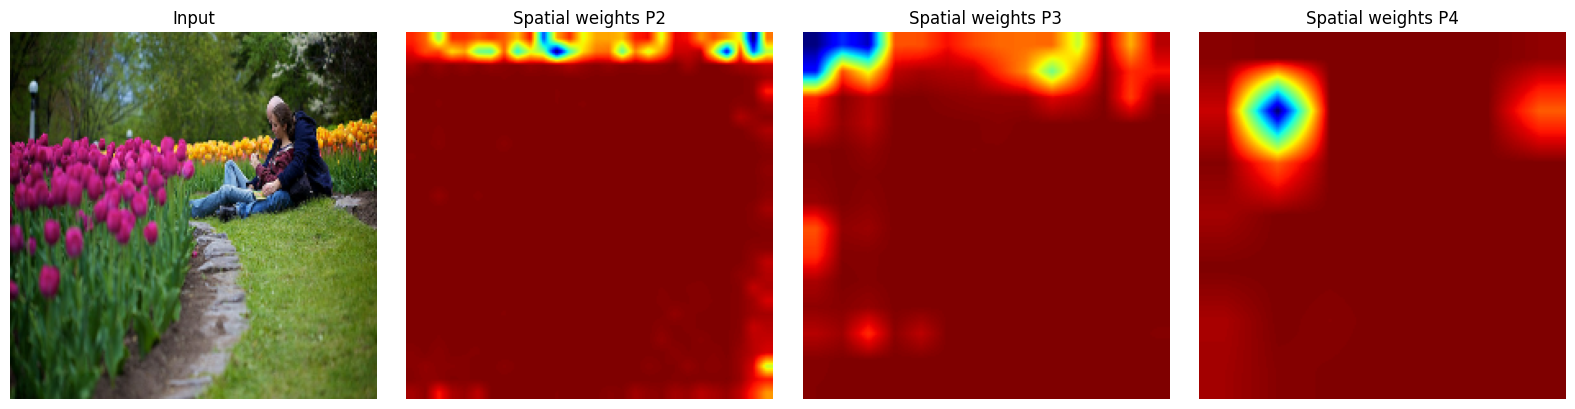

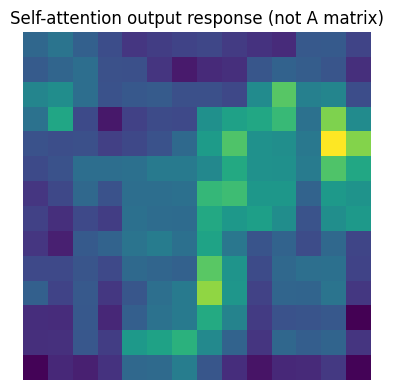

In [24]:
def trained_spatial_attention_map(model_name, image_batch):
    """Return the learned sigmoid spatial weights, not output/input ratios."""
    model = models[model_name]
    # Single-stage model names use the original layer name. Multi-stage variants
    # use suffixed names and can be passed explicitly through spatial_layer_name.
    candidates = [l.name for l in model.layers if l.name == "spatial_attention" or l.name.startswith("spatial_attention_")]
    if not candidates:
        raise ValueError(f"No spatial attention layer found in {model_name}")
    layer_name = candidates[-1]
    layer = model.get_layer(layer_name)
    probe = Model(model.inputs, layer.output)
    feature = probe(image_batch, training=False)
    # The layer output is feature * sigmoid_map. Build a second probe to retrieve
    # the spatial layer's input and calculate the map via the layer's conv weights.
    feature_input = Model(model.inputs, layer.input)(image_batch, training=False)
    avg_map = tf.reduce_mean(feature_input, axis=-1, keepdims=True)
    max_map = tf.reduce_max(feature_input, axis=-1, keepdims=True)
    weights = layer.conv(tf.concat([avg_map, max_map], axis=-1))
    return tf.nn.sigmoid(weights).numpy()[0]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(resized_img.astype("uint8")); axes[0].set_title("Input"); axes[0].axis("off")
for ax, pos, model_name in zip(axes[1:], ["P2", "P3", "P4"],
                               ["ChannelSpatial_P2", "ChannelSpatial_P3", "ChannelSpatial_P4"]):
    amap = trained_spatial_attention_map(model_name, x_img)
    amap = tf.image.resize(amap, (IMG_SIZE, IMG_SIZE)).numpy().squeeze()
    ax.imshow(amap, cmap="jet"); ax.set_title(f"Spatial weights {pos}"); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{RESULT_DIR}/13_attention_positions_P2_P3_P4.png", dpi=160, bbox_inches="tight"); plt.show()

# The self-attention layer's actual N×N matrix is not exposed as a model output
# by default. This feature-response visualization is not the attention matrix.
self_model = models["SelfAttention_P3"]
self_layer = self_model.get_layer("self_attention")
self_response = Model(self_model.inputs, self_layer.output)(x_img, training=False).numpy()[0]
response_map = np.mean(np.abs(self_response), axis=-1)
plt.figure(figsize=(5, 4)); plt.imshow(response_map, cmap="viridis")
plt.title("Self-attention output response (not A matrix)"); plt.axis("off")
plt.tight_layout(); plt.savefig(f"{RESULT_DIR}/14_self_attention_response.png", dpi=160, bbox_inches="tight"); plt.show()


## Task 10 — Optional ablation experiments

These optional comparisons examine attention order, spatial kernel size, and the SE and ECA channel-attention methods. They use the existing train, validation, and test split. Uncomment and run the relevant blocks only if you want to perform these additional training runs.


In [25]:
# Optional controlled ablations. Set RUN_EXTENDED_ABLATIONS=True near the top
# before running the notebook to train these additional models.
RUN_EXTENDED_ABLATIONS = False
if RUN_EXTENDED_ABLATIONS:
    # Attention order at P3: Channel -> Spatial versus Spatial -> Channel
    for name, order in [("ChannelThenSpatial_P3", "channel_spatial"),
                        ("SpatialThenChannel_P3", "spatial_channel")]:
        models[name], histories[name] = train_one(name, "order", "P3", order=order)
        models[name].save(f"{RESULT_DIR}/{name}.keras")

    # Spatial kernel-size ablation at P3
    for k in [3, 5, 7]:
        name = f"SpatialKernel{k}_P3"
        models[name], histories[name] = train_one(name, "spatial", "P3", kernel_size=k)
        models[name].save(f"{RESULT_DIR}/{name}.keras")

    # Two additional established channel-attention mechanisms
    for name, attention in [("SE_P3", "extra_se"), ("ECA_P3", "extra_eca")]:
        models[name], histories[name] = train_one(name, attention, "P3")
        models[name].save(f"{RESULT_DIR}/{name}.keras")

    # Keep an updated final-results table after optional runs.
    print("Extended ablations trained. Run the final evaluation cell again.")
else:
    print("Extended ablations skipped. Set RUN_EXTENDED_ABLATIONS=True and rerun this cell to include them.")


Extended ablations skipped. Set RUN_EXTENDED_ABLATIONS=True and rerun this cell to include them.


## Task 12 — Assemble the final results table

Run this after evaluating the models you want to include. The cell reevaluates the models currently stored in `models` and saves a combined CSV file; optional models are included if you trained and added them.


In [26]:
# Re-evaluate every model currently stored in `models` and save one final table.
all_results = []
all_predictions = {}
for name, model in models.items():
    r = evaluate_model(model, name)
    all_predictions[name] = (r.pop("y_true"), r.pop("y_pred"))
    all_results.append(r)
final_results_df = pd.DataFrame(all_results)
display(final_results_df.round(4))
final_results_df.to_csv(f"{RESULT_DIR}/final_all_results.csv", index=False)
print("Saved final table to", f"{RESULT_DIR}/final_all_results.csv")

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Trainable Parameters,Total Parameters,Inference Time (s/image)
0,Baseline,0.9183,0.9165,0.9192,0.9175,10245,23597957,0.0169
1,Channel_P3,0.9129,0.9138,0.9140,0.9118,142405,23730117,0.0174
2,Spatial_P3,0.9183,0.9175,0.9194,0.9182,10343,23598055,0.0174
3,ChannelSpatial_P3,0.9238,0.9223,0.9235,0.9227,142503,23730215,0.0175
4,ChannelSpatial_P2,0.9093,0.9092,0.9106,0.9094,43655,23631367,0.0175
5,ChannelSpatial_P4,0.9220,0.9208,0.9235,0.9219,536807,24124519,0.0176
6,SelfAttention_P3,0.9365,0.9358,0.9361,0.9356,1189894,24777606,0.0176
7,CombinedAll_P3,0.9129,0.9149,0.9100,0.9122,1322152,24909864,0.0181
8,ChannelSpatial_P3_P4,0.9201,0.9193,0.9201,0.9197,669065,24256777,0.0178


Saved final table to results/final_all_results.csv


## Task 11 — Qualitative error analysis (correct and incorrect predictions)

Use the same test examples for all models. The next cell selects up to three correct and two incorrect predictions for each available model and displays the true/predicted labels and confidence. Discuss only what is visible; do not infer causal explanations from an image alone.


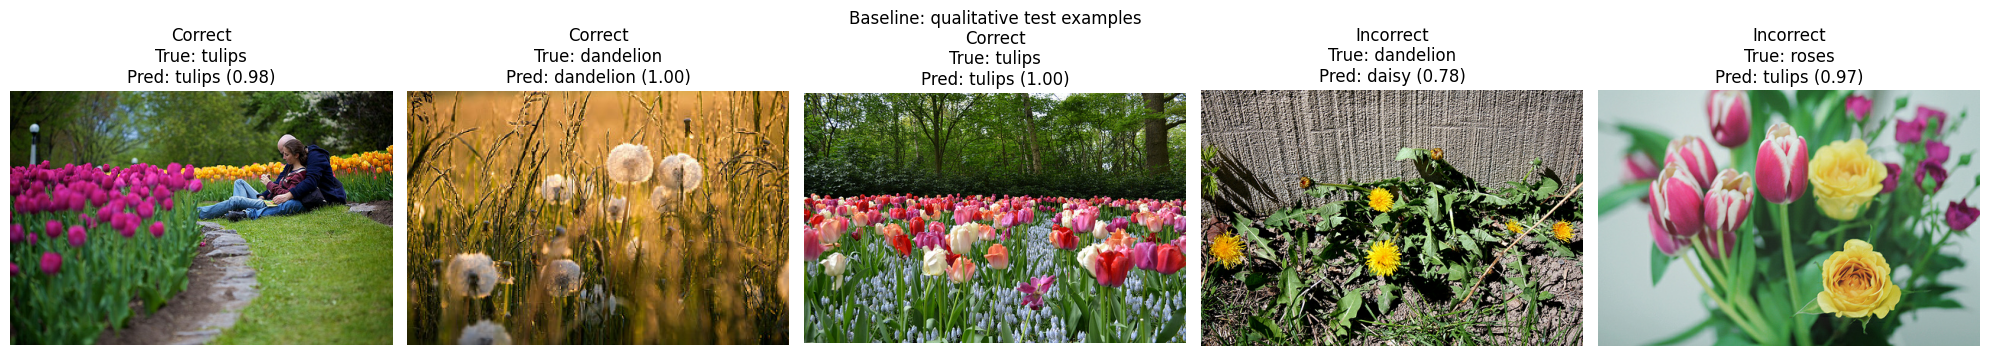

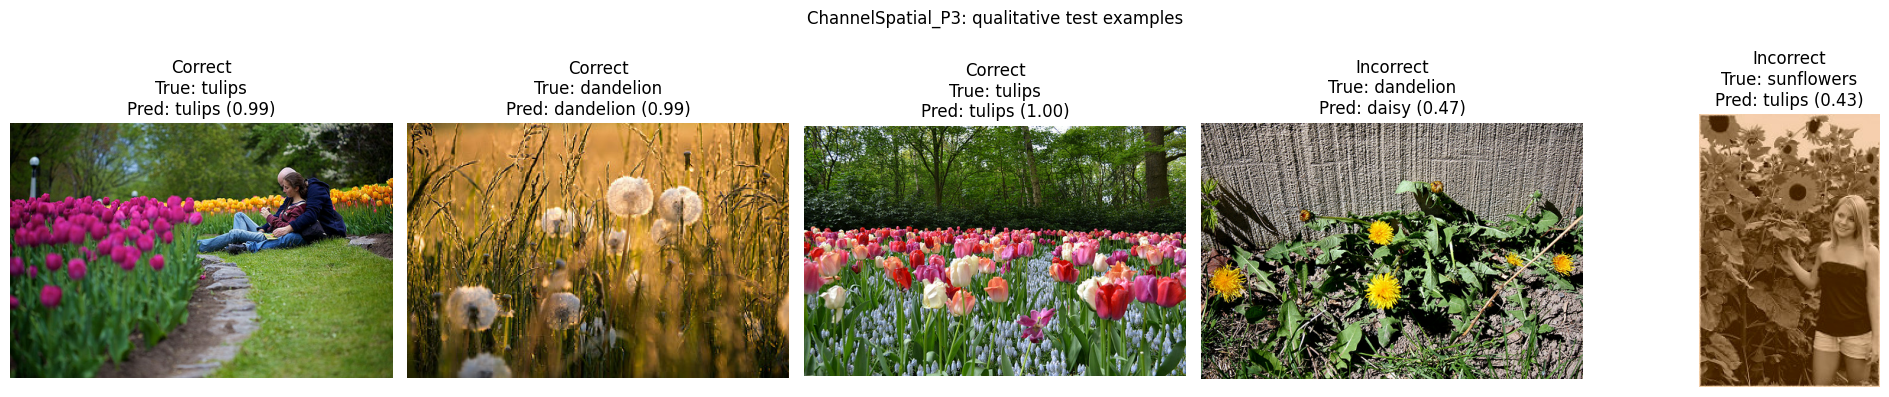

In [27]:
def show_correct_incorrect_examples(model_name, max_correct=3, max_incorrect=2):
    model = models[model_name]
    correct, incorrect = [], []
    for idx in range(len(test_idx)):
        raw = images[test_idx[idx]]
        label = int(labels[test_idx[idx]])
        xb = tf.expand_dims(preprocess_image(raw, label, training=False)[0], 0)
        prob = model.predict(xb, verbose=0)[0]
        pred = int(np.argmax(prob))
        item = (raw, label, pred, float(prob[pred]))
        (correct if pred == label else incorrect).append(item)
        if len(correct) >= max_correct and len(incorrect) >= max_incorrect:
            break
    items = [("Correct", x) for x in correct[:max_correct]] + [("Incorrect", x) for x in incorrect[:max_incorrect]]
    if not items:
        print("No examples available."); return
    fig, axes = plt.subplots(1, len(items), figsize=(4 * len(items), 4))
    if len(items) == 1: axes = [axes]
    for ax, (kind, (img, true_id, pred_id, conf)) in zip(axes, items):
        ax.imshow(img); ax.set_title(f"{kind}\nTrue: {class_names[true_id]}\nPred: {class_names[pred_id]} ({conf:.2f})")
        ax.axis("off")
    plt.suptitle(f"{model_name}: qualitative test examples")
    plt.tight_layout(); plt.show()

show_correct_incorrect_examples("Baseline")
show_correct_incorrect_examples("ChannelSpatial_P3")


## Task 13 — Report checklist and viva preparation

Use the actual results and plots from your run to support the discussion. Avoid claiming that an attention method is superior unless the measured test results support that conclusion.

1. **Residual connections:** Shortcut paths help gradients flow through deep networks and make deeper models easier to optimize.
2. **Early and late ResNet stages:** Earlier stages preserve finer spatial detail and respond to edges or textures; later stages have lower resolution and more semantic features.
3. **Downsampling:** Reducing spatial resolution lowers computation and combines local information into broader representations.
4. **Increasing channel depth:** Deeper stages can represent a wider range of increasingly complex patterns.
5. **Feature levels:** Low-level features include edges and colors; intermediate features capture patterns and parts; high-level features are more class-related.
6. **Why use attention:** Attention reweights features so that useful information can have more influence.
7. **Channel attention:** Learns which feature channels are more useful.
8. **Spatial attention:** Learns which feature-map locations are more useful.
9. **Channel versus spatial attention:** The former weights channels; the latter weights positions.
10. **Sequential attention:** The first module changes the features that the second module receives, so reversing the order can change the result.
11. **Stage-dependent channel attention:** Channels at different depths encode different types of information.
12. **Intermediate-stage spatial attention:** These maps can retain useful object-part details while providing more semantic information than very early features.
13. **Cost of self-attention:** With N = H × W spatial positions, the attention matrix contains N × N entries.
14. **Resolution and attention cost:** Doubling both height and width makes N four times larger and the N × N matrix sixteen times larger.
15. **Choosing an attention stage:** Compare the measured P2, P3, and P4 results rather than assuming a stage will perform best.
16. **P2 and P4 maps:** P2 generally contains finer spatial detail, while P4 is coarser and more semantic. Check whether your plots show this pattern.
17. **Does extra attention always help?** No. It can add computation, overfit, or duplicate information already represented by the backbone.
18. **Channel-then-spatial versus spatial-then-channel:** The order affects the input to the second module; use test metrics to compare them.
19. **Spatial kernel size:** A larger kernel considers a wider neighborhood and may cost more. Compare the tested kernel sizes rather than assuming a larger one is better.
20. **SE and ECA:** SE uses a bottleneck multilayer perceptron for channel weighting; ECA uses a lightweight one-dimensional convolution over the channel descriptor.
21. **CBAM:** Combines channel and spatial attention in sequence.
22. **Self-attention versus channel attention:** Self-attention relates spatial positions to one another, while channel attention reweights channels.
23. **Parameter count and accuracy:** A model with more parameters is not automatically more accurate or better at generalizing.
24. **Internal attention and Grad-CAM:** Internal attention weights come from an attention module; Grad-CAM derives a heatmap using gradients for a prediction.
25. **Why Grad-CAM is post-hoc:** It explains a selected prediction after the model has been defined and trained.
26. **Background suppression:** Inspect the overlays and describe only the regions that are visibly emphasized or suppressed.
27. **Correct and incorrect predictions:** Examine multiple test images from both groups before drawing conclusions.
28. **Class-wise performance:** Use per-class precision and recall, along with the confusion matrices, to identify classes that benefit or struggle.
29. **Confusion matrices:** Show which true classes are being predicted as other classes.
30. **Macro-F1:** Gives each class equal weight, so weak performance on a class is less likely to be hidden by overall accuracy.
31. **Accuracy versus complexity:** Consider whether an accuracy improvement justifies additional parameters or computation.
32. **Macro-F1 versus inference time:** Decide whether a score improvement is worth slower predictions.
33. **Fixed data split:** Keeps the comparison fair by evaluating each model on the same examples.
34. **Fixed training procedure:** Reduces other sources of variation so the model design is easier to compare.
35. **Grad-CAM interpretation:** Describe the regions highlighted in each example and avoid claims that the heatmap alone cannot establish.

36. **Correct architecture:** Attention is inserted after the chosen stage and its output is passed through all later ResNet50 stages. State the chosen insertion position and tensor dimensions.
37. **Combined attention:** Compare the trained channel + spatial + self-attention model against the simpler variants using the same split and metrics.
38. **Multi-stage attention:** Compare P3-only channel–spatial attention with P3 followed by P4 attention; report both accuracy and complexity.
39. **Run integrity:** All final tables must be regenerated after the last training run. Do not combine metrics from older model checkpoints with new models.

### Report reminder

Include the result table, learning curves, confusion matrices, attention visualizations, and Grad-CAM comparisons required by the manual. The generated files are saved in the `results/` folder.
